# 05 — Départs des femmes : quels facteurs, et sont-ils propres aux femmes ?
Objectif : identifier les facteurs associés au départ des **femmes** et vérifier s'ils diffèrent de ceux des hommes, pour fonder des recommandations RH.

| Section | Outil | Question |
|---|---|---|
| 1 | Écart H/F, test, standardisation, OR ajusté | Les femmes partent-elles plus ou moins, à profil égal ? |
| 2 | Tests univariés sur les femmes (Holm) | Quelles variables distinguent partantes et restantes ? |
| 3 | Régression logistique sur les femmes | Quels facteurs pèsent, toutes choses égales par ailleurs ? |
| 4 | Interactions Genre × facteur | Un facteur pèse-t-il différemment chez les femmes ? |
| 5 | Courbes de survie (Kaplan-Meier, log-rank) | À quelle ancienneté les femmes partent-elles ? |
| 6 | Arbre de décision | Quels segments de femmes sont les plus à risque ? |
| 7 | Décomposition d'Oaxaca-Blinder | L'écart H/F vient-il de la composition des effectifs ? |
| 8 | Scénarios « et si » avec bootstrap | Combien de départs un levier permettrait-il d'éviter ? |
| 9 | Stabilité (bootstrap, importance par permutation) | Les facteurs retenus sont-ils robustes ? |
| 10 | Équité salariale et promotion | Un sentiment de sous-rémunération relative accompagne-t-il les départs ? |
| 11 | Tableau de synthèse | Que retenir ? |

**Précautions.** Avec 89 départs féminins, la puissance est limitée : les modèles sont volontairement parcimonieux et les tests multiples corrigés (Holm). Les résultats décrivent des associations, pas des causes. Les motifs propres aux femmes (maternité, évolution bloquée, climat, flexibilité) ne figurent pas dans les données.

In [1]:
from pathlib import Path
import sys, warnings
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").exists():
    raise RuntimeError("Lancer depuis la racine du projet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import chi2
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.outliers_influence import variance_inflation_factor
from src.data import load_data, export_table, attrition_table
from src.plots import plot_attrition, save_figure
df = load_data()

In [2]:
# Variables dérivées (indicateurs binaires lisibles)
df["femme"] = (df.Gender == "Female").astype(int)
df["heures_sup"] = (df.OverTime == "Yes").astype(int)
df["voyages_frequents"] = (df.BusinessTravel == "Travel_Frequently").astype(int)
df["celibataire"] = (df.MaritalStatus == "Single").astype(int)
df["revenu_k"] = df.MonthlyIncome / 1000
df["log_revenu"] = np.log(df.MonthlyIncome)
F = df[df.femme == 1].copy()
H = df[df.femme == 0].copy()

LABELS = {
    "heures_sup": "Heures supplémentaires (oui vs non)",
    "voyages_frequents": "Voyages fréquents (vs autres)",
    "celibataire": "Célibataire (vs autres)",
    "DistanceFromHome": "Distance au domicile (par unité)",
    "JobSatisfaction": "Satisfaction au poste (par point)",
    "EnvironmentSatisfaction": "Satisfaction environnement (par point)",
    "WorkLifeBalance": "Équilibre vie pro/perso (par point)",
    "revenu_k": "Revenu mensuel (par 1 000)",
    "Age": "Âge (par an)",
    "YearsSinceLastPromotion": "Années depuis dernière promotion (par an)",
    "NumCompaniesWorked": "Entreprises précédentes (par entreprise)",
    "YearsWithCurrManager": "Années avec le manager actuel (par an)",
    "StockOptionLevel": "Niveau de stock-options (par niveau)",
    "TrainingTimesLastYear": "Formations l'an dernier (par formation)",
}

def holm(p):
    return multipletests(p, method="holm")[1]

def or_table(res):
    ci = res.conf_int()
    t = pd.DataFrame({"odds_ratio": np.exp(res.params), "ic95_bas": np.exp(ci[0]),
                      "ic95_haut": np.exp(ci[1]), "p": res.pvalues})
    return t.drop(index="Intercept", errors="ignore")

display(pd.DataFrame({"effectif": [len(F), len(H)], "departs": [F.depart.sum(), H.depart.sum()],
                      "proportion_depart": [F.depart.mean(), H.depart.mean()]}, index=["Femmes", "Hommes"]))

,effectif,departs,proportion_depart
Femmes,605,89,0.147107
Hommes,913,159,0.174151


## 1. Écart de départs femmes / hommes
Trois lectures complémentaires : l'écart brut avec son test, un **ratio standardisé (SMR)** qui applique aux femmes les taux de départ des hommes à métier et niveau identiques (SMR < 1 : elles partent moins que prévu), et un **odds ratio ajusté** dans un modèle logistique.

In [3]:
g = attrition_table(df, "Gender").set_index("Gender")
g["ic95_bas"], g["ic95_haut"] = proportion_confint(g.departs, g.effectif, method="wilson")
display(g)
pF, pM = g.loc["Female", "proportion_depart"], g.loc["Male", "proportion_depart"]
nF, nM = g.loc["Female", "effectif"], g.loc["Male", "effectif"]
diff = pF - pM
se = np.sqrt(pF * (1 - pF) / nF + pM * (1 - pM) / nM)
_, p_brut = proportions_ztest([g.loc["Female", "departs"], g.loc["Male", "departs"]], [nF, nM])

# SMR : taux des hommes par métier x niveau appliqués aux femmes
strates = ["JobRole", "JobLevel"]
FF = F.join(H.groupby(strates).depart.mean().rename("taux_H"), on=strates)
couverture = FF.taux_H.notna().mean()
FFc = FF.dropna(subset=["taux_H"])
obs, att = FFc.depart.sum(), FFc.taux_H.sum()
smr = obs / att
smr_lo, smr_hi = chi2.ppf(.025, 2 * obs) / 2 / att, chi2.ppf(.975, 2 * (obs + 1)) / 2 / att

# OR ajusté
m_adj = smf.logit("depart ~ femme + C(JobRole) + C(JobLevel) + heures_sup + voyages_frequents + celibataire"
                  " + Age + revenu_k + YearsAtCompany", df).fit(disp=0)
or_adj = or_table(m_adj).loc["femme"]

ecart = pd.DataFrame([
    {"mesure": "Écart brut (points de %, F - H)", "valeur": diff * 100,
     "ic95_bas": (diff - 1.96 * se) * 100, "ic95_haut": (diff + 1.96 * se) * 100, "p": p_brut},
    {"mesure": "SMR (taux H par métier x niveau)", "valeur": smr, "ic95_bas": smr_lo, "ic95_haut": smr_hi, "p": np.nan},
    {"mesure": "OR ajusté Femme vs Homme", "valeur": or_adj.odds_ratio,
     "ic95_bas": or_adj.ic95_bas, "ic95_haut": or_adj.ic95_haut, "p": or_adj.p},
])
display(export_table(ecart, "05_ecart_genre"))
print(f"SMR calculé sur {couverture:.0%} des femmes (strates métier x niveau couvertes par des hommes) : "
      f"{obs} départs observés contre {att:.1f} attendus.")

,effectif,departs,proportion_depart,ic95_bas,ic95_haut
Gender,,,,,
Female,605,89,0.147107,0.121110,0.177558
Male,913,159,0.174151,0.150931,0.200102


,mesure,valeur,ic95_bas,ic95_haut,p
0,"Écart brut (points de %, F - H)",-2.704371,-6.448487,1.039745,0.162906
1,SMR (taux H par métier x niveau),0.902240,0.723623,1.111585,NaN
2,OR ajusté Femme vs Homme,0.754113,0.545510,1.042484,0.087611


SMR calculé sur 99% des femmes (strates métier x niveau couvertes par des hommes) : 88 départs observés contre 97.5 attendus.


## 2. Profil des partantes : tests univariés sur les femmes
Chaque variable est comparée entre partantes (n=89) et restantes. Tests : χ² (variables catégorielles, effet V de Cramér) et Mann-Whitney (variables numériques, effet = corrélation bisériale par rangs). Les p-values sont corrigées par la méthode de Holm sur l'ensemble des tests. Les catégories de moins de 20 femmes sont ignorées pour le repérage de la modalité la plus à risque.

,variable,type,test,p,effet,mesure_effet,detail,p_holm
0,Age,numérique,Mann-Whitney,9.294755e-09,0.380672,corrélation bisériale par rangs,médiane partantes 31.0 vs restantes 37.0,2.416636e-07
1,TotalWorkingYears,numérique,Mann-Whitney,2.205636e-08,0.370307,corrélation bisériale par rangs,médiane partantes 7.0 vs restantes 10.0,5.514089e-07
2,MonthlyIncome,numérique,Mann-Whitney,8.792312e-08,0.354847,corrélation bisériale par rangs,médiane partantes 2886.0 vs restantes 5378.0,2.110155e-06
3,JobLevel,catégorielle,χ²,9.479931e-08,0.260254,V de Cramér,1 : 27% de départs,2.180384e-06
4,JobRole,catégorielle,χ²,1.355960e-07,0.279551,V de Cramér,Sales Representative : 44% de départs,2.983112e-06
5,OverTime,catégorielle,χ²,2.395503e-06,0.191766,V de Cramér,Yes : 25% de départs,5.030557e-05
6,StockOptionLevel,catégorielle,χ²,3.155743e-06,0.216244,V de Cramér,0 : 23% de départs,6.311485e-05
7,MaritalStatus,catégorielle,χ²,2.340525e-05,0.187745,V de Cramér,Single : 24% de départs,4.446998e-04
8,YearsAtCompany,numérique,Mann-Whitney,8.886988e-05,0.259058,corrélation bisériale par rangs,médiane partantes 4.0 vs restantes 6.0,1.599658e-03
9,BusinessTravel,catégorielle,χ²,2.563202e-04,0.165335,V de Cramér,Travel_Frequently : 26% de départs,4.357443e-03


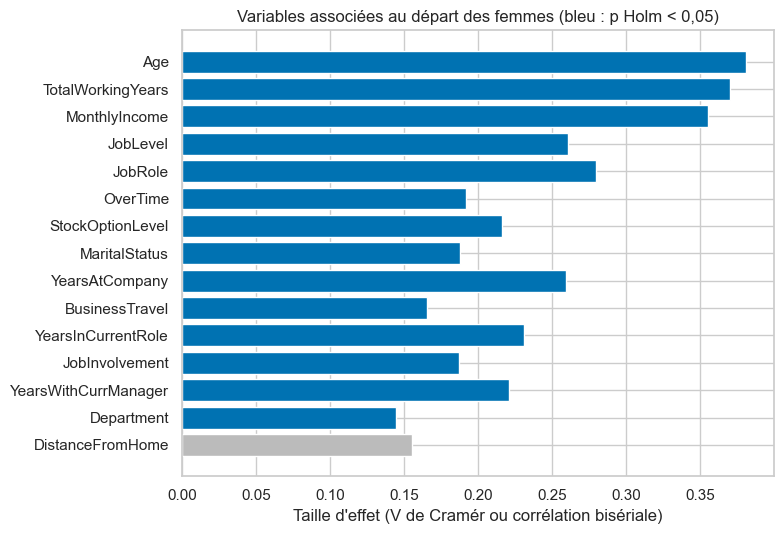

In [4]:
cats = ["BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus", "OverTime", "JobLevel",
        "StockOptionLevel", "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
        "RelationshipSatisfaction", "JobInvolvement", "PerformanceRating", "Education"]
nums = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager", "NumCompaniesWorked", "PercentSalaryHike",
        "TrainingTimesLastYear"]
rows = []
for c in cats:
    ct = pd.crosstab(F[c], F.depart)
    chi, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi / (ct.values.sum() * (min(ct.shape) - 1)))
    grp = F.groupby(c).depart.agg(["size", "mean"])
    grp = grp[grp["size"] >= 20]
    detail = f"{grp['mean'].idxmax()} : {grp['mean'].max():.0%} de départs" if len(grp) else ""
    rows.append(dict(variable=c, type="catégorielle", test="χ²", p=p, effet=v, mesure_effet="V de Cramér", detail=detail))
for c in nums:
    a, b = F.loc[F.depart == 1, c], F.loc[F.depart == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    auc = u / (len(a) * len(b))
    rows.append(dict(variable=c, type="numérique", test="Mann-Whitney", p=p, effet=2 * abs(auc - .5),
                     mesure_effet="corrélation bisériale par rangs",
                     detail=f"médiane partantes {a.median():.1f} vs restantes {b.median():.1f}"))
univ = pd.DataFrame(rows)
univ["p_holm"] = holm(univ.p)
univ = univ.sort_values("p").reset_index(drop=True)
display(export_table(univ, "05_tests_univaries"))

top = univ.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.variable, top.effet, color=np.where(top.p_holm < .05, "#0072B2", "#bbbbbb"))
ax.set(xlabel="Taille d'effet (V de Cramér ou corrélation bisériale)", title="Variables associées au départ des femmes (bleu : p Holm < 0,05)")
save_figure(fig, "05_univaries_femmes")

## 3. Régression logistique sur les femmes
Dix variables au plus, pour respecter une règle empirique d'environ 10 départs par paramètre (ici 89 départs). Les niveaux de satisfaction sont traités comme des scores linéaires (échelles non validées : lecture indicative). Les voyages sont regroupés en « fréquents vs autres » car la modalité « sans voyage » ne compte que trois départs. Contrôles : multicolinéarité (VIF) et performance en validation croisée répétée.

,libelle,odds_ratio,ic95_bas,ic95_haut,p,variable
0,Heures supplémentaires (oui vs non),3.855041,2.286644,6.499194,4.112535e-07,heures_sup
1,Voyages fréquents (vs autres),2.536174,1.444881,4.451702,1.186877e-03,voyages_frequents
2,Célibataire (vs autres),2.538552,1.511868,4.262438,4.263692e-04,celibataire
3,Distance au domicile (par unité),1.038188,1.007563,1.069743,1.415912e-02,DistanceFromHome
4,Satisfaction au poste (par point),0.685093,0.541678,0.866478,1.600157e-03,JobSatisfaction
5,Satisfaction environnement (par point),0.661096,0.523824,0.834341,4.918770e-04,EnvironmentSatisfaction
6,Équilibre vie pro/perso (par point),1.050935,0.739069,1.494401,7.820959e-01,WorkLifeBalance
7,Revenu mensuel (par 1 000),0.882891,0.808589,0.964020,5.487441e-03,revenu_k
8,Âge (par an),0.940595,0.907837,0.974534,7.084370e-04,Age
9,Années depuis dernière promotion (par an),1.060915,0.971740,1.158273,1.868296e-01,YearsSinceLastPromotion


Départs : 89 pour 10 paramètres, soit 8.9 départs par paramètre (cible : 10).


,VIF
heures_sup,1.01
voyages_frequents,1.02
celibataire,1.04
DistanceFromHome,1.02
JobSatisfaction,1.01
EnvironmentSatisfaction,1.01
WorkLifeBalance,1.02
revenu_k,1.43
Age,1.38
YearsSinceLastPromotion,1.10


Aucun VIF > 5 : pas de multicolinéarité préoccupante.


AUC en validation croisée (5 plis x 10 répétitions) : 0.789 (écart-type 0.060)


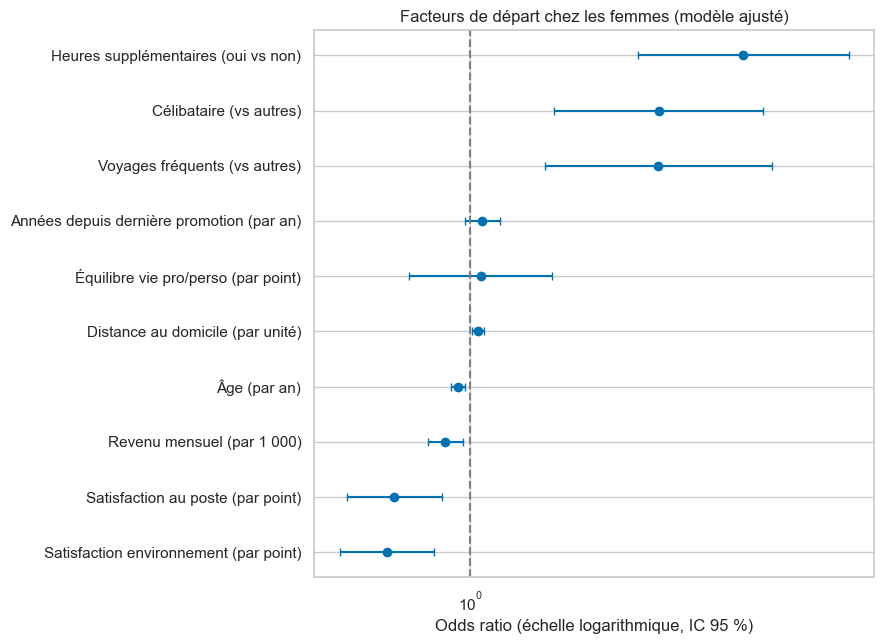

In [5]:
VARS = ["heures_sup", "voyages_frequents", "celibataire", "DistanceFromHome", "JobSatisfaction",
        "EnvironmentSatisfaction", "WorkLifeBalance", "revenu_k", "Age", "YearsSinceLastPromotion"]
FORMULE_F = "depart ~ " + " + ".join(VARS)
res_f = smf.logit(FORMULE_F, F).fit(disp=0)
tab_f = or_table(res_f)
tab_f.index = [LABELS.get(i, i) for i in tab_f.index]
tab_f["variable"] = VARS
display(export_table(tab_f.reset_index(names="libelle"), "05_logit_femmes"))
n_param = len(res_f.params) - 1
print(f"Départs : {int(F.depart.sum())} pour {n_param} paramètres, soit {F.depart.sum() / n_param:.1f} départs par paramètre (cible : 10).")

X = res_f.model.exog
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=VARS, name="VIF")
display(vif.round(2).to_frame())
print("VIF > 5 : multicolinéarité à surveiller." if (vif > 5).any() else "Aucun VIF > 5 : pas de multicolinéarité préoccupante.")

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
pipe = Pipeline([("echelle", StandardScaler()), ("logit", LogisticRegression(C=1, max_iter=2000))])
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
auc_cv = cross_val_score(pipe, F[VARS], F.depart, cv=cv, scoring="roc_auc")
print(f"AUC en validation croisée (5 plis x 10 répétitions) : {auc_cv.mean():.3f} (écart-type {auc_cv.std():.3f})")

def forest(tab, title, name, label_col=None):
    t = tab.sort_values("odds_ratio")
    fig, ax = plt.subplots(figsize=(9, .5 * len(t) + 1.6))
    ax.errorbar(t.odds_ratio, range(len(t)), xerr=[t.odds_ratio - t.ic95_bas, t.ic95_haut - t.odds_ratio],
                fmt="o", capsize=3, color="#0072B2")
    ax.axvline(1, color="grey", ls="--")
    ax.set(xscale="log", yticks=range(len(t)), xlabel="Odds ratio (échelle logarithmique, IC 95 %)", title=title)
    ax.set_yticklabels(t.index if label_col is None else t[label_col])
    save_figure(fig, name)

forest(tab_f, "Facteurs de départ chez les femmes (modèle ajusté)", "05_forest_femmes")

## 4. Les facteurs pèsent-ils différemment chez les femmes ?
Pour chaque facteur : OR estimé chez les femmes, OR chez les hommes (mêmes contrôles : âge, ancienneté, niveau) et **test d'interaction** Genre × facteur sur l'ensemble des salariés. Les p-values d'interaction sont corrigées par Holm. Un ratio d'OR > 1 signifie que le facteur augmente davantage le risque chez les femmes.

,facteur,libelle,OR_femmes,ic_f_bas,ic_f_haut,OR_hommes,ic_h_bas,ic_h_haut,ratio_OR_F_sur_H,p_interaction,p_holm
0,NumCompaniesWorked,Entreprises précédentes (par entreprise),1.038254,0.938918,1.148101,1.161812,1.079517,1.250381,0.846608,0.004637,0.060275
1,WorkLifeBalance,Équilibre vie pro/perso (par point),1.102209,0.789074,1.539607,0.739613,0.588052,0.930237,1.491440,0.048083,0.576995
2,YearsWithCurrManager,Années avec le manager actuel (par an),0.903702,0.809289,1.009129,0.887690,0.805494,0.978273,1.062286,0.208321,1.000000
3,TrainingTimesLastYear,Formations l'an dernier (par formation),0.794795,0.659145,0.958362,0.915181,0.797878,1.049731,0.877171,0.260498,1.000000
4,heures_sup,Heures supplémentaires (oui vs non),3.643195,2.212259,5.999694,4.361081,3.001905,6.335653,0.728869,0.306478,1.000000
5,YearsSinceLastPromotion,Années depuis dernière promotion (par an),1.016142,0.917942,1.124846,1.194035,1.092906,1.304521,0.956674,0.373460,1.000000
6,revenu_k,Revenu mensuel (par 1 000),0.896347,0.750102,1.071104,0.889703,0.783035,1.010902,0.970983,0.463336,1.000000
7,EnvironmentSatisfaction,Satisfaction environnement (par point),0.701226,0.563597,0.872463,0.799128,0.684479,0.932981,0.907373,0.467782,1.000000
8,StockOptionLevel,Niveau de stock-options (par niveau),0.621137,0.442652,0.871590,0.678920,0.542936,0.848962,0.889922,0.568393,1.000000
9,DistanceFromHome,Distance au domicile (par unité),1.038175,1.009266,1.067912,1.026650,1.004923,1.048846,1.006206,0.725401,1.000000


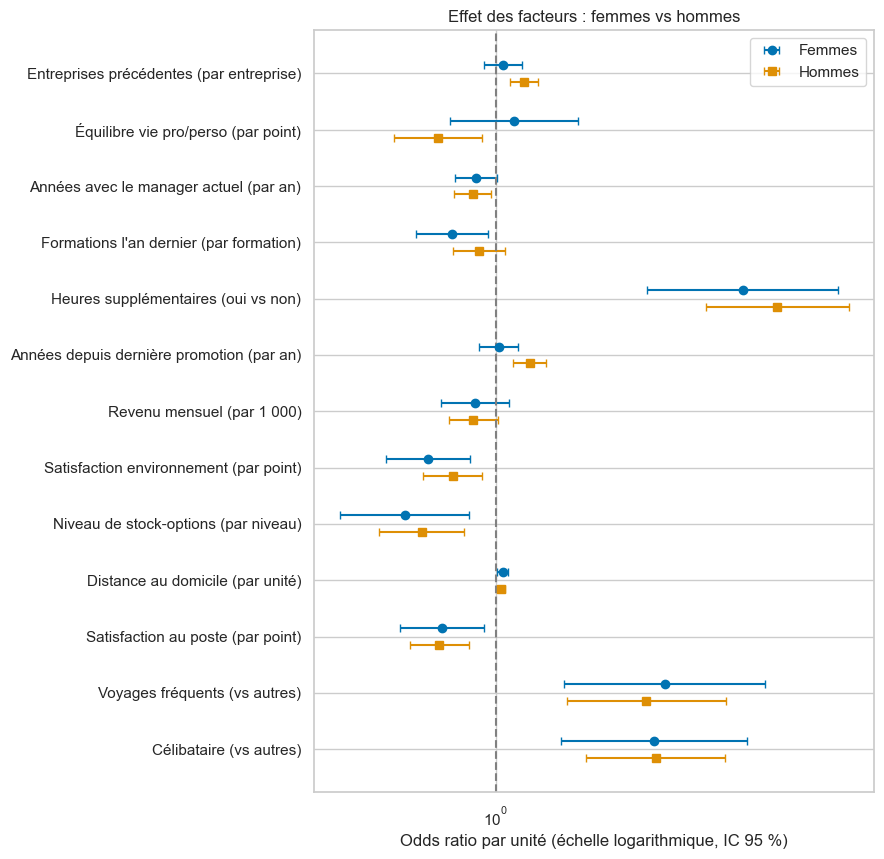

Interactions avec p Holm < 0,10 : NumCompaniesWorked


In [6]:
FACTEURS = ["heures_sup", "voyages_frequents", "celibataire", "DistanceFromHome", "JobSatisfaction",
            "EnvironmentSatisfaction", "WorkLifeBalance", "revenu_k", "YearsSinceLastPromotion",
            "NumCompaniesWorked", "YearsWithCurrManager", "StockOptionLevel", "TrainingTimesLastYear"]
CTRL = "Age + YearsAtCompany + C(JobLevel)"
rows = []
for f in FACTEURS:
    mi = smf.logit(f"depart ~ femme * {f} + {CTRL}", df).fit(disp=0)
    mf = smf.logit(f"depart ~ {f} + {CTRL}", F).fit(disp=0)
    mh = smf.logit(f"depart ~ {f} + {CTRL}", H).fit(disp=0)
    tf, th = or_table(mf).loc[f], or_table(mh).loc[f]
    k = f"femme:{f}"
    rows.append(dict(facteur=f, libelle=LABELS[f], OR_femmes=tf.odds_ratio, ic_f_bas=tf.ic95_bas, ic_f_haut=tf.ic95_haut,
                     OR_hommes=th.odds_ratio, ic_h_bas=th.ic95_bas, ic_h_haut=th.ic95_haut,
                     ratio_OR_F_sur_H=np.exp(mi.params[k]), p_interaction=mi.pvalues[k]))
inter = pd.DataFrame(rows)
inter["p_holm"] = holm(inter.p_interaction)
inter = inter.sort_values("p_interaction").reset_index(drop=True)
display(export_table(inter, "05_interactions_genre"))

t = inter.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, .55 * len(t) + 1.6))
y = np.arange(len(t))
ax.errorbar(t.OR_femmes, y + .15, xerr=[t.OR_femmes - t.ic_f_bas, t.ic_f_haut - t.OR_femmes], fmt="o", capsize=3, label="Femmes")
ax.errorbar(t.OR_hommes, y - .15, xerr=[t.OR_hommes - t.ic_h_bas, t.ic_h_haut - t.OR_hommes], fmt="s", capsize=3, label="Hommes")
ax.axvline(1, color="grey", ls="--")
ax.set(xscale="log", yticks=y, xlabel="Odds ratio par unité (échelle logarithmique, IC 95 %)", title="Effet des facteurs : femmes vs hommes")
ax.set_yticklabels(t.libelle)
ax.legend()
save_figure(fig, "05_interactions_genre")
sig = inter[inter.p_holm < .10]
print("Interactions avec p Holm < 0,10 :", ", ".join(sig.facteur) if len(sig) else "aucune après correction pour tests multiples.")

## 5. Courbes de survie : à quelle ancienneté les femmes partent-elles ?
Durée = `YearsAtCompany` (ancienneté au départ pour les partants, ancienneté actuelle pour les restants, qui sont censurés). Estimateur de Kaplan-Meier avec intervalle de Greenwood, test du log-rank. L'ancienneté est en années entières ; les résultats sont une lecture descriptive par ancienneté, pas un taux annuel.

,groupe,effectif,restent_apres_1_ans,restent_apres_3_ans,restent_apres_5_ans,restent_apres_10_ans
0,Femmes,605,0.956316,0.924386,0.892161,0.796388
1,Hommes,913,0.940928,0.899949,0.856089,0.759881
2,Femmes sans heures sup,418,0.970703,0.946603,0.933319,0.869971
3,Femmes avec heures sup,187,0.924487,0.875332,0.801712,0.629893


Log-rank Femmes vs Hommes : p = 0.109
Log-rank Femmes avec vs sans heures sup : p = 0.0000


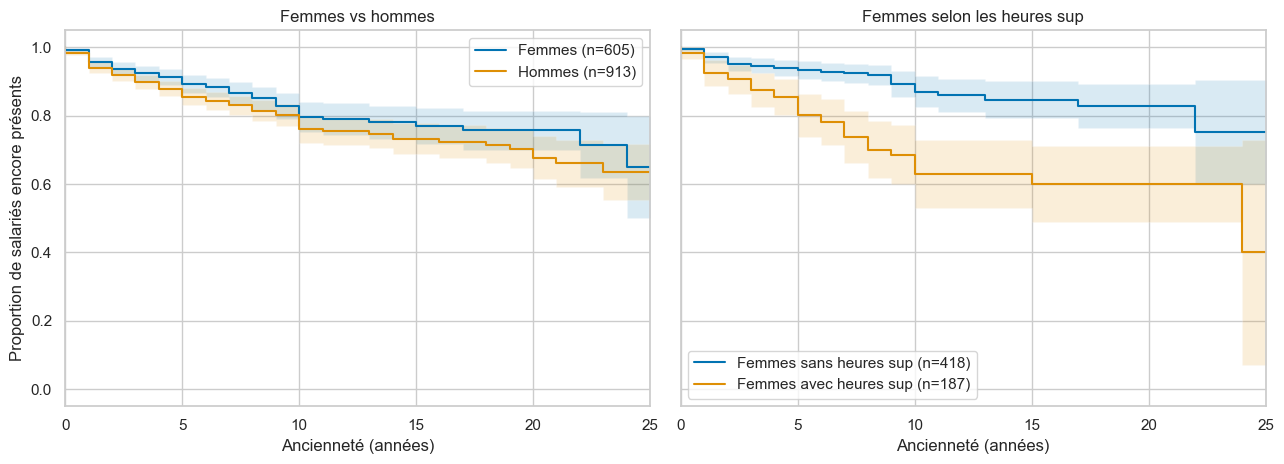

In [7]:
def kaplan_meier(duree, evt):
    d = pd.DataFrame({"t": np.asarray(duree), "e": np.asarray(evt)})
    S, v, rows = 1.0, 0.0, [(0, 1.0, 1.0, 1.0)]
    for t in np.sort(d.t.unique()):
        n = (d.t >= t).sum()
        k = ((d.t == t) & (d.e == 1)).sum()
        if k > 0:
            S *= 1 - k / n
            if n > k:
                v += k / (n * (n - k))
        se = S * np.sqrt(v)
        rows.append((t, S, max(S - 1.96 * se, 0), min(S + 1.96 * se, 1)))
    return pd.DataFrame(rows, columns=["t", "S", "bas", "haut"])

def logrank(t1, e1, t2, e2):
    t1, e1, t2, e2 = map(np.asarray, (t1, e1, t2, e2))
    O1 = E1 = V = 0.0
    for t in np.unique(np.concatenate([t1[e1 == 1], t2[e2 == 1]])):
        n1, n2 = (t1 >= t).sum(), (t2 >= t).sum()
        n = n1 + n2
        d1, d2 = ((t1 == t) & (e1 == 1)).sum(), ((t2 == t) & (e2 == 1)).sum()
        d = d1 + d2
        O1 += d1
        E1 += d * n1 / n
        if n > 1:
            V += d * (n1 / n) * (1 - n1 / n) * (n - d) / (n - 1)
    chi = (O1 - E1) ** 2 / V
    return chi, 1 - chi2.cdf(chi, 1)

def surv_at(km, t):
    return km.loc[km.t <= t].iloc[-1]

groupes = {"Femmes": F, "Hommes": H,
           "Femmes sans heures sup": F[F.heures_sup == 0], "Femmes avec heures sup": F[F.heures_sup == 1]}
kms = {k: kaplan_meier(v.YearsAtCompany, v.depart) for k, v in groupes.items()}
rows = []
for k, km in kms.items():
    r = {"groupe": k, "effectif": len(groupes[k])}
    for t in [1, 3, 5, 10]:
        s = surv_at(km, t)
        r[f"restent_apres_{t}_ans"] = s.S
    rows.append(r)
surv = pd.DataFrame(rows)
chi_hf, p_hf = logrank(F.YearsAtCompany, F.depart, H.YearsAtCompany, H.depart)
a, b = groupes["Femmes sans heures sup"], groupes["Femmes avec heures sup"]
chi_ot, p_ot = logrank(a.YearsAtCompany, a.depart, b.YearsAtCompany, b.depart)
display(export_table(surv, "05_survie"))
print(f"Log-rank Femmes vs Hommes : p = {p_hf:.3f}")
print(f"Log-rank Femmes avec vs sans heures sup : p = {p_ot:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, noms, titre in [(axes[0], ["Femmes", "Hommes"], "Femmes vs hommes"),
                        (axes[1], ["Femmes sans heures sup", "Femmes avec heures sup"], "Femmes selon les heures sup")]:
    for k in noms:
        km = kms[k]
        ax.step(km.t, km.S, where="post", label=f"{k} (n={len(groupes[k])})")
        ax.fill_between(km.t, km.bas, km.haut, step="post", alpha=.15)
    ax.set(xlabel="Ancienneté (années)", title=titre, xlim=(0, 25))
    ax.legend()
axes[0].set_ylabel("Proportion de salariés encore présents")
save_figure(fig, "05_survie")

## 6. Segments de femmes à risque : arbre de décision
Un arbre peu profond isole des profils interprétables. La profondeur est choisie par validation croisée (AUC) ; l'AUC de sélection est légèrement optimiste. Chaque feuille est décrite avec son intervalle de Wilson : les petites feuilles sont indicatives.

,AUC validation croisée
profondeur,
2,0.674721
3,0.719321
4,0.733097


Profondeur retenue : 4


,effectif,departs,proportion_depart,ic95_bas,ic95_haut,lift_vs_moyenne,profil,part_des_departs
0,44,26,0.590909,0.444098,0.723121,4.016854,revenu_k <= 2.9 ET heures_sup > 0.5,0.292135
1,48,16,0.333333,0.216768,0.474599,2.265918,revenu_k <= 2.9 ET heures_sup <= 0.5 ET Age <= 31.5,0.179775
2,30,10,0.333333,0.192305,0.512199,2.265918,revenu_k > 2.9 ET DistanceFromHome > 10.5 ET EnvironmentSatisfaction <= 2.5 ET revenu_k <= 5.9,0.112360
3,30,7,0.233333,0.117924,0.409283,1.586142,revenu_k > 2.9 ET DistanceFromHome > 10.5 ET EnvironmentSatisfaction <= 2.5 ET revenu_k > 5.9,0.078652
4,40,8,0.200000,0.105000,0.347573,1.359551,revenu_k > 2.9 ET DistanceFromHome <= 10.5 ET StockOptionLevel <= 0.5 ET JobSatisfaction <= 2.5,0.089888
5,41,7,0.170732,0.085253,0.312626,1.160592,revenu_k > 2.9 ET DistanceFromHome > 10.5 ET EnvironmentSatisfaction > 2.5 ET revenu_k > 6.7,0.078652
6,45,4,0.088889,0.035111,0.207336,0.604245,revenu_k <= 2.9 ET heures_sup <= 0.5 ET Age > 31.5,0.044944
7,50,3,0.060000,0.020615,0.162171,0.407865,revenu_k > 2.9 ET DistanceFromHome <= 10.5 ET StockOptionLevel > 0.5 ET Age > 45.5,0.033708
8,84,5,0.059524,0.025691,0.131883,0.404628,revenu_k > 2.9 ET DistanceFromHome <= 10.5 ET StockOptionLevel <= 0.5 ET JobSatisfaction > 2.5,0.056180
9,49,1,0.020408,0.003612,0.106935,0.138730,revenu_k > 2.9 ET DistanceFromHome > 10.5 ET EnvironmentSatisfaction > 2.5 ET revenu_k <= 6.7,0.011236


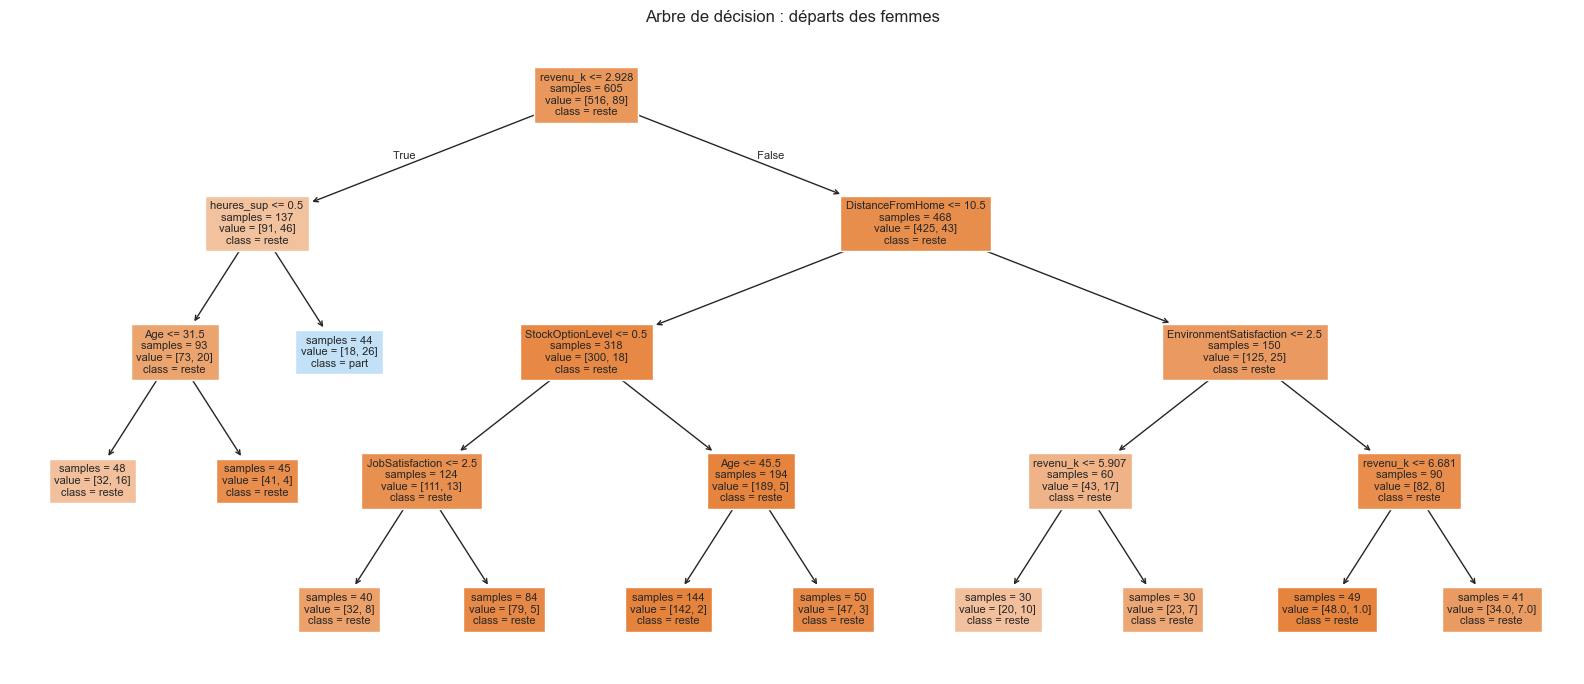

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
FEATS = ["heures_sup", "voyages_frequents", "celibataire", "JobLevel", "Age", "revenu_k", "DistanceFromHome",
         "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "YearsAtCompany", "StockOptionLevel",
         "NumCompaniesWorked"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
res_depth = {}
for depth in [2, 3, 4]:
    arbre = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=30, random_state=42)
    res_depth[depth] = cross_val_score(arbre, F[FEATS], F.depart, cv=cv, scoring="roc_auc").mean()
display(pd.Series(res_depth, name="AUC validation croisée").rename_axis("profondeur").to_frame())
best = max(res_depth, key=res_depth.get)
tree = DecisionTreeClassifier(max_depth=best, min_samples_leaf=30, random_state=42).fit(F[FEATS], F.depart)
print("Profondeur retenue :", best)

def leaf_rules(tree, names):
    t, rules = tree.tree_, {}
    def rec(node, conds):
        if t.children_left[node] == -1:
            rules[node] = " ET ".join(conds) if conds else "(toutes)"
            return
        nom, thr = names[t.feature[node]], t.threshold[node]
        rec(t.children_left[node], conds + [f"{nom} <= {thr:.1f}"])
        rec(t.children_right[node], conds + [f"{nom} > {thr:.1f}"])
    rec(0, [])
    return rules

regles = leaf_rules(tree, FEATS)
F["_feuille"] = tree.apply(F[FEATS])
seg = F.groupby("_feuille").depart.agg(effectif="size", departs="sum", proportion_depart="mean").reset_index()
seg["ic95_bas"], seg["ic95_haut"] = proportion_confint(seg.departs, seg.effectif, method="wilson")
seg["lift_vs_moyenne"] = seg.proportion_depart / F.depart.mean()
seg["profil"] = seg["_feuille"].map(regles)
seg = seg.drop(columns="_feuille").sort_values("proportion_depart", ascending=False).reset_index(drop=True)
seg["part_des_departs"] = seg.departs / F.depart.sum()
pd.set_option("display.max_colwidth", 120)
display(export_table(seg, "05_segments_femmes"))
F = F.drop(columns="_feuille")

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, feature_names=FEATS, class_names=["reste", "part"], filled=True, impurity=False, proportion=False, fontsize=8, ax=ax)
ax.set_title("Arbre de décision : départs des femmes")
save_figure(fig, "05_arbre_femmes")

## 7. Décomposition d'Oaxaca-Blinder de l'écart H/F
Modèle de probabilité linéaire (départ ∈ {0,1}) avec coefficients de référence poolés (Neumark). L'écart H − F se décompose en une part **expliquée** par des différences de composition (niveau, métier, heures sup, âge, revenu, etc.) et une part **non expliquée** (traitements différents des mêmes caractéristiques, ou facteurs non observés). Intervalles par bootstrap (500 réplicats). Un écart H − F positif signifie que les hommes partent davantage.

In [9]:
from patsy import dmatrix
Xd = dmatrix("C(JobLevel) + C(JobRole) + heures_sup + voyages_frequents + celibataire + Age + revenu_k"
             " + YearsAtCompany + DistanceFromHome + JobSatisfaction + EnvironmentSatisfaction", df, return_type="dataframe")
XA, yA, fA = Xd.to_numpy(float), df.depart.to_numpy(float), (df.femme == 1).to_numpy()

def oaxaca(X, y, f):
    XF, XH, yF, yH = X[f], X[~f], y[f], y[~f]
    beta = lambda A, v: np.linalg.lstsq(A, v, rcond=None)[0]
    bF, bH, bP = beta(XF, yF), beta(XH, yH), beta(X, y)
    mF, mH = XF.mean(0), XH.mean(0)
    return yH.mean() - yF.mean(), (mH - mF) @ bP, mH @ (bH - bP) + mF @ (bP - bF)

tot, expl, nexpl = oaxaca(XA, yA, fA)
rng = np.random.default_rng(42)
boot = []
for _ in range(500):
    i = rng.integers(0, len(yA), len(yA))
    boot.append(oaxaca(XA[i], yA[i], fA[i]))
boot = np.array(boot)
ob = pd.DataFrame({"composante": ["Écart total (H - F)", "Expliqué par la composition", "Non expliqué"],
                   "points_de_pourcentage": np.array([tot, expl, nexpl]) * 100,
                   "ic95_bas": np.percentile(boot, 2.5, axis=0) * 100,
                   "ic95_haut": np.percentile(boot, 97.5, axis=0) * 100})
display(export_table(ob, "05_oaxaca"))
print("Si l'IC d'une composante contient 0, elle n'est pas distinguable de zéro.")

,composante,points_de_pourcentage,ic95_bas,ic95_haut
0,Écart total (H - F),2.704371,-1.196375,6.363550
1,Expliqué par la composition,-0.322072,-2.350547,1.428939
2,Non expliqué,3.026444,-0.376394,6.407243


Si l'IC d'une composante contient 0, elle n'est pas distinguable de zéro.


## 8. Scénarios « et si » : départs de femmes évités
On applique le modèle logistique de la section 3 à des scénarios contrefactuels et on mesure la variation du nombre de départs attendus. L'intervalle vient d'un bootstrap (300 réplicats) qui réestime le modèle. **Hypothèse forte** : l'association estimée est supposée causale ; ce sont des ordres de grandeur pour hiérarchiser les leviers, pas des prévisions.

300 réplicats bootstrap valides sur 300.


,scenario,femmes_concernees,departs_attendus_base,departs_evites,ic95_bas,ic95_haut,reduction_relative
0,Combiné (heures sup niveau 1 + satisfactions >= 3),410,89.0,38.996888,27.605758,51.506790,0.438167
1,Aucune heure supplémentaire,187,89.0,27.692773,17.109709,40.089001,0.311155
2,Satisfaction environnement d'au moins 3,233,89.0,15.586637,6.752995,25.208536,0.175131
3,Satisfaction au poste d'au moins 3,242,89.0,14.090697,6.124077,22.632280,0.158322
4,Pas de voyages fréquents,120,89.0,13.769194,4.303135,22.364809,0.154710
5,Aucune heure sup (niveau 1 seulement),60,89.0,12.625731,7.760426,18.364533,0.141862
6,Distance au domicile plafonnée à 15,135,89.0,4.529514,0.727978,8.865999,0.050893
7,Revenu +10 %,605,89.0,3.656988,0.947347,5.927793,0.041090


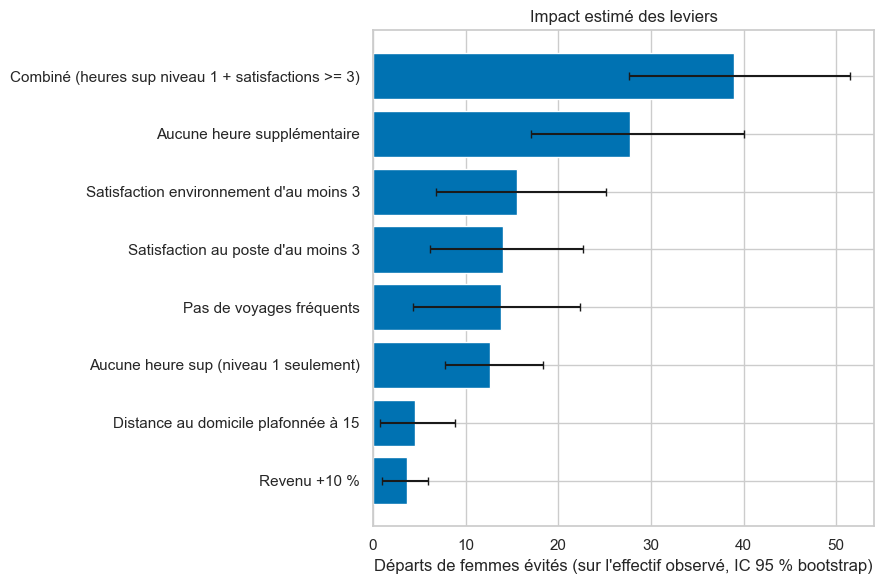

In [10]:
def bootstrap_logit(data, formula, B=300, seed=42):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        sample = data.iloc[rng.integers(0, len(data), len(data))]
        try:
            out.append(smf.logit(formula, sample).fit(disp=0, maxiter=100))
        except Exception:
            continue
    return out

boots = bootstrap_logit(F, FORMULE_F)
print(f"{len(boots)} réplicats bootstrap valides sur 300.")

SCENARIOS = {
    "Aucune heure supplémentaire": lambda d: d.assign(heures_sup=0),
    "Aucune heure sup (niveau 1 seulement)": lambda d: d.assign(heures_sup=np.where(d.JobLevel == 1, 0, d.heures_sup)),
    "Pas de voyages fréquents": lambda d: d.assign(voyages_frequents=0),
    "Satisfaction au poste d'au moins 3": lambda d: d.assign(JobSatisfaction=np.maximum(d.JobSatisfaction, 3)),
    "Satisfaction environnement d'au moins 3": lambda d: d.assign(EnvironmentSatisfaction=np.maximum(d.EnvironmentSatisfaction, 3)),
    "Distance au domicile plafonnée à 15": lambda d: d.assign(DistanceFromHome=np.minimum(d.DistanceFromHome, 15)),
    "Revenu +10 %": lambda d: d.assign(revenu_k=d.revenu_k * 1.1),
}
SCENARIOS["Combiné (heures sup niveau 1 + satisfactions >= 3)"] = lambda d: SCENARIOS["Satisfaction environnement d'au moins 3"](
    SCENARIOS["Satisfaction au poste d'au moins 3"](SCENARIOS["Aucune heure sup (niveau 1 seulement)"](d)))

base = res_f.predict(F).sum()
rows = []
for nom, fn in SCENARIOS.items():
    Fs = fn(F)
    evites = base - res_f.predict(Fs).sum()
    ev_boot = np.array([b.predict(F).sum() - b.predict(Fs).sum() for b in boots])
    rows.append(dict(scenario=nom, femmes_concernees=int((Fs[VARS].values != F[VARS].values).any(axis=1).sum()),
                     departs_attendus_base=base, departs_evites=evites,
                     ic95_bas=np.percentile(ev_boot, 2.5), ic95_haut=np.percentile(ev_boot, 97.5),
                     reduction_relative=evites / base))
scen = pd.DataFrame(rows).sort_values("departs_evites", ascending=False).reset_index(drop=True)
display(export_table(scen, "05_scenarios"))

t = scen.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, .55 * len(t) + 1.6))
ax.barh(t.scenario, t.departs_evites, xerr=[t.departs_evites - t.ic95_bas, t.ic95_haut - t.departs_evites], capsize=3, color="#0072B2")
ax.set(xlabel="Départs de femmes évités (sur l'effectif observé, IC 95 % bootstrap)", title="Impact estimé des leviers")
save_figure(fig, "05_scenarios")

## 9. Robustesse des facteurs retenus
Deux contrôles : (i) **stabilité bootstrap** — part des réplicats où le facteur est significatif (p < 0,05) avec le même signe que le modèle principal ; (ii) **importance par permutation** — perte d'AUC hors échantillon quand on mélange la variable (validation croisée). Un facteur robuste est stable sur les deux critères.

,variable,libelle,OR_principal,part_replicats_significatifs,OR_bootstrap_ic_bas,OR_bootstrap_ic_haut,perte_auc_permutation
0,heures_sup,Heures supplémentaires (oui vs non),3.855041,1.000000,2.506319,7.653028,0.062670
1,Age,Âge (par an),0.940595,0.916667,0.896324,0.976475,0.044400
2,revenu_k,Revenu mensuel (par 1 000),0.882891,0.763333,0.766805,0.973224,0.039015
3,celibataire,Célibataire (vs autres),2.538552,0.943333,1.573485,4.164610,0.030115
4,EnvironmentSatisfaction,Satisfaction environnement (par point),0.661096,0.950000,0.503209,0.817763,0.023717
5,JobSatisfaction,Satisfaction au poste (par point),0.685093,0.883333,0.523770,0.851785,0.019402
6,voyages_frequents,Voyages fréquents (vs autres),2.536174,0.880000,1.375337,4.628895,0.018457
7,DistanceFromHome,Distance au domicile (par unité),1.038188,0.686667,1.007198,1.070156,0.009306
8,YearsSinceLastPromotion,Années depuis dernière promotion (par an),1.060915,0.340000,0.958066,1.166618,-0.000003
9,WorkLifeBalance,Équilibre vie pro/perso (par point),1.050935,0.083333,0.703350,1.645100,-0.005431


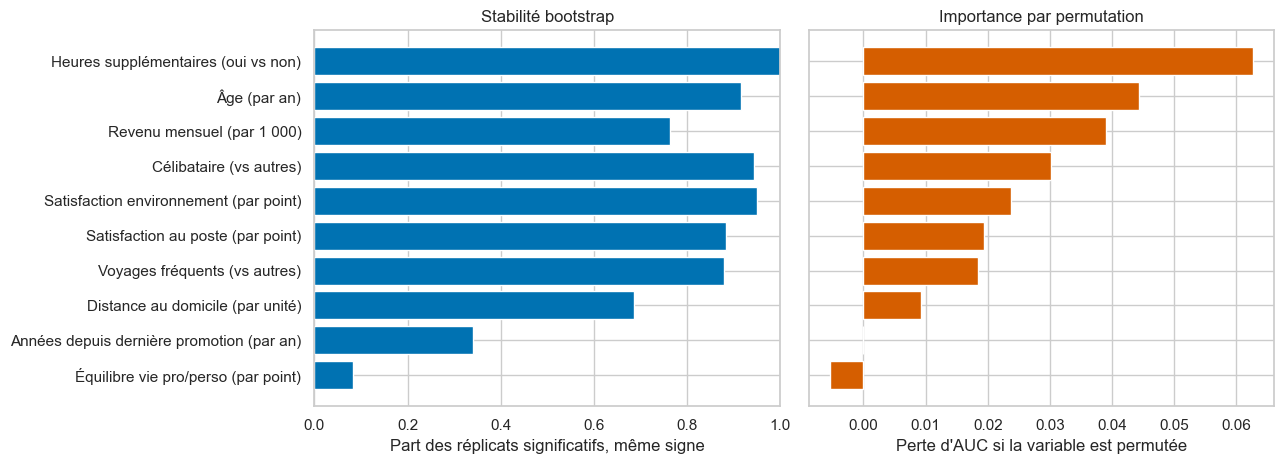

In [11]:
from sklearn.inspection import permutation_importance
ref_sign = np.sign(res_f.params[VARS])
rows = []
for v in VARS:
    p = np.array([b.pvalues[v] for b in boots]); c = np.array([b.params[v] for b in boots])
    rows.append(dict(variable=v, libelle=LABELS[v],
                     OR_principal=np.exp(res_f.params[v]),
                     part_replicats_significatifs=np.mean((p < .05) & (np.sign(c) == ref_sign[v])),
                     OR_bootstrap_ic_bas=np.exp(np.percentile(c, 2.5)), OR_bootstrap_ic_haut=np.exp(np.percentile(c, 97.5))))
stab = pd.DataFrame(rows)

imps = []
for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(F[VARS], F.depart):
    pipe.fit(F.iloc[tr][VARS], F.depart.iloc[tr])
    r = permutation_importance(pipe, F.iloc[te][VARS], F.depart.iloc[te], scoring="roc_auc", n_repeats=10, random_state=42)
    imps.append(r.importances_mean)
stab["perte_auc_permutation"] = np.mean(imps, axis=0)
stab = stab.sort_values("perte_auc_permutation", ascending=False).reset_index(drop=True)
display(export_table(stab, "05_stabilite"))

t = stab.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
axes[0].barh(t.libelle, t.part_replicats_significatifs, color="#0072B2")
axes[0].set(xlabel="Part des réplicats significatifs, même signe", xlim=(0, 1), title="Stabilité bootstrap")
axes[1].barh(t.libelle, t.perte_auc_permutation, color="#D55E00")
axes[1].set(xlabel="Perte d'AUC si la variable est permutée", title="Importance par permutation")
save_figure(fig, "05_robustesse")

## 10. Équité : rémunération, promotion et départs
(a) Écart de rémunération ajusté (régression sur le log du revenu, à niveau, métier, expérience et ancienneté comparables) ; (b) écart de délai depuis la dernière promotion à niveau et métier comparables ; (c) **sous-rémunération relative** : revenu observé des femmes rapporté au revenu attendu d'un homme de même niveau, métier et expérience, puis taux de départ par quartile.

In [12]:
m_pay = smf.ols("log_revenu ~ femme + C(JobLevel) + C(JobRole) + TotalWorkingYears + YearsAtCompany", df).fit()
m_pro = smf.ols("YearsSinceLastPromotion ~ femme + C(JobLevel) + C(JobRole) + YearsAtCompany + YearsInCurrentRole", df).fit()
ci_pay, ci_pro = m_pay.conf_int().loc["femme"], m_pro.conf_int().loc["femme"]
equite = pd.DataFrame([
    {"mesure": "Écart de revenu ajusté, femmes vs hommes (%)", "valeur": (np.exp(m_pay.params["femme"]) - 1) * 100,
     "ic95_bas": (np.exp(ci_pay[0]) - 1) * 100, "ic95_haut": (np.exp(ci_pay[1]) - 1) * 100, "p": m_pay.pvalues["femme"]},
    {"mesure": "Écart de délai depuis dernière promotion ajusté (années, F - H)", "valeur": m_pro.params["femme"],
     "ic95_bas": ci_pro[0], "ic95_haut": ci_pro[1], "p": m_pro.pvalues["femme"]},
])
display(export_table(equite, "05_equite"))

# (c) Revenu attendu d'après les hommes
m_ref = smf.ols("log_revenu ~ C(JobLevel) + C(JobRole) + TotalWorkingYears + YearsAtCompany", H).fit()
F["ratio_revenu_attendu"] = np.exp(F.log_revenu - m_ref.predict(F))
F["quartile_ratio"] = pd.qcut(F.ratio_revenu_attendu, 4, labels=["Q1 (le plus bas)", "Q2", "Q3", "Q4 (le plus haut)"])
q = F.groupby("quartile_ratio", observed=True).agg(effectif=("depart", "size"), departs=("depart", "sum"),
                                                   proportion_depart=("depart", "mean"),
                                                   ratio_median=("ratio_revenu_attendu", "median")).reset_index()
display(export_table(q, "05_sous_remuneration_quartiles"))
F["log_ratio"] = np.log(F.ratio_revenu_attendu)
m_q = smf.logit("depart ~ log_ratio + C(JobLevel) + heures_sup", F).fit(disp=0)
or10 = np.exp(m_q.params["log_ratio"] * np.log(1.1))
ci = np.exp(m_q.conf_int().loc["log_ratio"] * np.log(1.1))
print(f"OR de départ pour +10 % de revenu relatif (ajusté niveau et heures sup) : {or10:.2f} "
      f"[{min(ci):.2f} ; {max(ci):.2f}], p = {m_q.pvalues['log_ratio']:.3f}")
F = F.drop(columns=["ratio_revenu_attendu", "quartile_ratio", "log_ratio"])

,mesure,valeur,ic95_bas,ic95_haut,p
0,"Écart de revenu ajusté, femmes vs hommes (%)",-0.190832,-2.542545,2.217629,0.875157
1,"Écart de délai depuis dernière promotion ajusté (années, F - H)",0.019455,-0.239291,0.278201,0.882766


,quartile_ratio,effectif,departs,proportion_depart,ratio_median
0,Q1 (le plus bas),152,28,0.184211,0.794114
1,Q2,151,25,0.165563,0.944897
2,Q3,151,15,0.099338,1.047980
3,Q4 (le plus haut),151,21,0.139073,1.256863


OR de départ pour +10 % de revenu relatif (ajusté niveau et heures sup) : 0.94 [0.85 ; 1.04], p = 0.198


## 11. Tableau de synthèse
Rassemble les résultats clés pour la lecture client. La conclusion rédigée suit le tableau.

In [13]:
sig_f = tab_f[tab_f.p < .05].copy()
sig_f = sig_f.join(stab.set_index("libelle")[["part_replicats_significatifs", "perte_auc_permutation"]])
sig_f = sig_f.sort_values("p")
print("Facteurs significatifs chez les femmes (modèle ajusté, p < 0,05) :")
display(sig_f[["odds_ratio", "ic95_bas", "ic95_haut", "p", "part_replicats_significatifs", "perte_auc_permutation"]].round(3))
print("\nÉcart de départs F/H :")
display(ecart.round(3))
print("\nInteractions Genre x facteur (p le plus faible) :")
display(inter[["libelle", "OR_femmes", "OR_hommes", "ratio_OR_F_sur_H", "p_interaction", "p_holm"]].head(3).round(3))
print("\nLevier le plus efficace :")
display(scen[["scenario", "departs_evites", "ic95_bas", "ic95_haut", "reduction_relative"]].head(3).round(3))
print("\nSegments les plus à risque :")
display(seg[["profil", "effectif", "departs", "proportion_depart", "part_des_departs"]].head(3).round(3))

Facteurs significatifs chez les femmes (modèle ajusté, p < 0,05) :


,odds_ratio,ic95_bas,ic95_haut,p,part_replicats_significatifs,perte_auc_permutation
Heures supplémentaires (oui vs non),3.855,2.287,6.499,0.000,1.000,0.063
Célibataire (vs autres),2.539,1.512,4.262,0.000,0.943,0.030
Satisfaction environnement (par point),0.661,0.524,0.834,0.000,0.950,0.024
Âge (par an),0.941,0.908,0.975,0.001,0.917,0.044
Voyages fréquents (vs autres),2.536,1.445,4.452,0.001,0.880,0.018
Satisfaction au poste (par point),0.685,0.542,0.866,0.002,0.883,0.019
Revenu mensuel (par 1 000),0.883,0.809,0.964,0.005,0.763,0.039
Distance au domicile (par unité),1.038,1.008,1.070,0.014,0.687,0.009



Écart de départs F/H :


,mesure,valeur,ic95_bas,ic95_haut,p
0,"Écart brut (points de %, F - H)",-2.704,-6.448,1.040,0.163
1,SMR (taux H par métier x niveau),0.902,0.724,1.112,NaN
2,OR ajusté Femme vs Homme,0.754,0.546,1.042,0.088



Interactions Genre x facteur (p le plus faible) :


,libelle,OR_femmes,OR_hommes,ratio_OR_F_sur_H,p_interaction,p_holm
0,Entreprises précédentes (par entreprise),1.038,1.162,0.847,0.005,0.060
1,Équilibre vie pro/perso (par point),1.102,0.740,1.491,0.048,0.577
2,Années avec le manager actuel (par an),0.904,0.888,1.062,0.208,1.000



Levier le plus efficace :


,scenario,departs_evites,ic95_bas,ic95_haut,reduction_relative
0,Combiné (heures sup niveau 1 + satisfactions >= 3),38.997,27.606,51.507,0.438
1,Aucune heure supplémentaire,27.693,17.110,40.089,0.311
2,Satisfaction environnement d'au moins 3,15.587,6.753,25.209,0.175



Segments les plus à risque :


,profil,effectif,departs,proportion_depart,part_des_departs
0,revenu_k <= 2.9 ET heures_sup > 0.5,44,26,0.591,0.292
1,revenu_k <= 2.9 ET heures_sup <= 0.5 ET Age <= 31.5,48,16,0.333,0.180
2,revenu_k > 2.9 ET DistanceFromHome > 10.5 ET EnvironmentSatisfaction <= 2.5 ET revenu_k <= 5.9,30,10,0.333,0.112


## Conclusion et recommandations

**1. Il n'y a pas de sur-départ des femmes.** 14,7 % des femmes sont parties contre 17,4 % des hommes (écart de -2,7 points, IC 95 % de -6,4 à +1,0, p = 0,16). À métier et niveau identiques, le SMR est de 0,90 (IC 0,72 à 1,11) ; l'OR ajusté est de 0,75 (IC 0,55 à 1,04). La décomposition d'Oaxaca-Blinder ne distingue pas de composante expliquée ou non expliquée de zéro. Le message au client : le sujet est la rétention de profils précis, pas un déficit de rétention féminine global.

**2. Les facteurs de départ des femmes sont solides et en grande partie communs aux hommes.** Dans le modèle ajusté sur les femmes (AUC de validation croisée d'environ 0,79) :
- heures supplémentaires : OR 3,9 (IC 2,3 à 6,5), significatif dans 100 % des réplicats bootstrap ;
- voyages fréquents : OR 2,5 ; célibataire : OR 2,5 ;
- satisfaction au poste (OR 0,69 par point) et de l'environnement (OR 0,66 par point) ;
- revenu (OR 0,88 par tranche de 1 000), âge (OR 0,94 par an), distance au domicile (OR 1,04 par unité) ;
- équilibre vie pro/perso et délai depuis la dernière promotion : pas d'effet net une fois les autres facteurs pris en compte.

**3. Aucun facteur n'agit significativement différemment chez les femmes après correction pour tests multiples.** La seule piste (p Holm = 0,06) : l'historique de mobilité (nombre d'entreprises précédentes) augmente le risque de départ des hommes (OR 1,16 par entreprise) mais pas celui des femmes (OR 1,04). L'équilibre vie pro/perso ressort à p = 0,048 avant correction (effet protecteur chez les hommes, nul chez les femmes) : à ne pas retenir sans confirmation.

**4. Le risque se concentre sur des segments identifiables.** Les femmes à faible revenu (≤ 2 900) avec heures supplémentaires partent à 59 % (26 sur 44, soit 29 % de tous les départs féminins). Celles à faible revenu, sans heures sup et de 31 ans ou moins partent à 33 % (16 sur 48). Ces deux segments, environ 15 % de l'effectif féminin, concentrent 47 % des départs. Les courbes de survie confirment l'effet des heures sup : 63 % des femmes avec heures sup sont encore présentes à 10 ans, contre 87 % sans.

**5. Pas de preuve d'inéquité salariale ou de promotion associée aux départs.** L'écart de revenu ajusté est de -0,2 % (IC -2,5 à +2,2 %) et l'écart de délai de promotion est de +0,02 an. La sous-rémunération relative n'est pas significativement liée au départ (OR 0,94 pour +10 % de revenu relatif, IC 0,85 à 1,04).

### Mesures à conseiller (par ordre d'impact estimé)
| Levier | Départs de femmes évités (sur 89) | Remarque |
|---|---|---|
| Plafonner les heures supplémentaires (niveau 1 en priorité) | environ 13 (niveau 1 seul) à 28 (toutes) | Levier n°1 ; cibler d'abord les postes juniors à bas revenu |
| Améliorer la satisfaction au poste et de l'environnement (au moins 3) | environ 14 et 15 | Entretiens de carrière, qualité du management et de l'environnement de travail |
| Limiter les voyages fréquents ou prévoir une compensation | environ 14 | Surtout pour les commerciaux et les profils célibataires |
| Combiner heures sup niveau 1 + satisfactions | environ 39 (IC 28 à 52) | Plan d'ensemble le plus efficace |
| Aménager la distance (télétravail, mobilité) | environ 5 | Effet modéré |
| Hausse générale de 10 % des revenus | environ 4 | Peu efficace ; préférer des mesures ciblées sur les bas revenus |

### Limites
- Associations, pas causes : les scénarios supposent que l'association estimée est causale et servent à hiérarchiser les leviers.
- Seulement 89 départs féminins : les intervalles sont larges, les petits segments et les petits métiers (par ex. RH) sont indicatifs.
- Les échelles de satisfaction ne sont pas documentées et sont traitées comme linéaires ; l'ancienneté est en années entières.
- Les motifs propres aux femmes (maternité, évolution de carrière bloquée, climat, flexibilité) ne sont pas dans les données : à explorer par entretiens de départ ou enquête auprès des femmes avant de conclure à l'absence de facteurs spécifiques.